In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.preprocessing import RobustScaler
from sklearn.preprocessing import LabelEncoder, OneHotEncoder
from sklearn.inspection import permutation_importance
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from xgboost import XGBClassifier
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [2]:
df = pd.read_csv(r'C:\Users\Caio_\OneDrive\Dokument\skolan\EdgeComputer\USA_Supply_data.csv', encoding="latin-1")
pd.set_option("display.max_columns", None)

In [3]:
df1 = pd.read_csv(r'C:\Users\Caio_\OneDrive\Dokument\skolan\EdgeComputer\DataCOSupplyChainDataset.csv', encoding="latin-1")


In [4]:
df.head(1)

,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,Customer Country,Customer Id,Customer Segment,Customer State,Customer Street,Customer Zipcode,Department Id,Department Name,Latitude,Longitude,Market,Order City,Order Country,Order Customer Id,order date (DateOrders),Order Id,Order Item Cardprod Id,Order Item Discount,Order Item Discount Rate,Order Item Id,Order Item Product Price,Order Item Profit Ratio,Order Item Quantity,Sales,Order Item Total,Order Profit Per Order,Order Region,Order State,Order Status,Order Zipcode,Product Card Id,Product Category Id,Product Image,Product Name,Product Price,Product Status,shipping date (DateOrders),Shipping Mode,Name
0,PAYMENT,2,2,22.41,74.68,Shipping on time,0,13,Electronics,Caguas,Puerto Rico,3296,Home Office,PR,8205 Silver Grove Row,725.0,3,Footwear,18.234663,-66.370598,USCA,Pasco,Estados Unidos,3296,6/11/2016 15:12,36146,278,15.3,0.17,90273,44.990002,0.3,2,89.980003,74.68,22.41,West of USA,Washington,PENDING_PAYMENT,99301.0,278,13,http://images.acmesports.sports/Under+Armour+M...,Under Armour Men's Compression EV SL Slide,44.990002,0,6/13/2016 15:12,Second Class,Mary Smith


In [5]:
df1.head(1)

,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,Customer Country,Customer Email,Customer Fname,Customer Id,Customer Lname,Customer Password,Customer Segment,Customer State,Customer Street,Customer Zipcode,Department Id,Department Name,Latitude,Longitude,Market,Order City,Order Country,Order Customer Id,order date (DateOrders),Order Id,Order Item Cardprod Id,Order Item Discount,Order Item Discount Rate,Order Item Id,Order Item Product Price,Order Item Profit Ratio,Order Item Quantity,Sales,Order Item Total,Order Profit Per Order,Order Region,Order State,Order Status,Order Zipcode,Product Card Id,Product Category Id,Product Description,Product Image,Product Name,Product Price,Product Status,shipping date (DateOrders),Shipping Mode
0,DEBIT,3,4,91.25,314.640015,Advance shipping,0,73,Sporting Goods,Caguas,Puerto Rico,XXXXXXXXX,Cally,20755,Holloway,XXXXXXXXX,Consumer,PR,5365 Noble Nectar Island,725.0,2,Fitness,18.251453,-66.037056,Pacific Asia,Bekasi,Indonesia,20755,1/31/2018 22:56,77202,1360,13.11,0.04,180517,327.75,0.29,1,327.75,314.640015,91.25,Southeast Asia,Java Occidental,COMPLETE,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2/3/2018 22:56,Standard Class


## Data cleaning

In [6]:
df.shape

(24840, 49)

In [7]:
print(df.isnull().sum())
print(df.duplicated().sum())
print(df[df.duplicated()])
print(df.dtypes)

Type                             0
Days for shipping (real)         0
Days for shipment (scheduled)    0
Benefit per order                0
Sales per customer               0
Delivery Status                  0
Late_delivery_risk               0
Category Id                      0
Category Name                    0
Customer City                    0
Customer Country                 0
Customer Id                      0
Customer Segment                 0
Customer State                   0
Customer Street                  0
Customer Zipcode                 0
Department Id                    0
Department Name                  0
Latitude                         0
Longitude                        0
Market                           0
Order City                       0
Order Country                    0
Order Customer Id                0
order date (DateOrders)          0
Order Id                         0
Order Item Cardprod Id           0
Order Item Discount              0
Order Item Discount 

In [8]:
df.shape

(24840, 49)

In [9]:
df[["Order State", "Customer City", "Delivery Status"]].value_counts()

Order State     Customer City  Delivery Status 
California      Caguas         Late delivery       966
Nueva York      Caguas         Late delivery       582
Texas           Caguas         Late delivery       450
California      Caguas         Advance shipping    418
                               Shipping on time    330
                                                  ... 
Dakota del Sur  Caguas         Advance shipping      1
Connecticut     Winnetka       Late delivery         1
Nueva York      Potomac        Late delivery         1
                               Advance shipping      1
Florida         Irving         Shipping on time      1
Name: count, Length: 4269, dtype: int64

In [10]:
df[
    (df["Order State"] == "California") & 
    (df["Customer City"] == "Caguas")
][["Order State", "Customer City", "Delivery Status", "Department Name"]].value_counts()

Order State  Customer City  Delivery Status    Department Name
California   Caguas         Late delivery      Fan Shop           370
                                               Apparel            282
                                               Golf               193
                            Advance shipping   Fan Shop           159
                            Shipping on time   Fan Shop           126
                            Advance shipping   Apparel            117
                            Shipping on time   Apparel             88
                            Advance shipping   Golf                77
                            Late delivery      Footwear            75
                            Shipping on time   Golf                66
                            Shipping canceled  Fan Shop            53
                                               Apparel             41
                            Late delivery      Outdoors            38
                           

In [11]:
df[
    (df["Order State"] == "Nueva York") & 
    (df["Customer City"] == "Caguas")
][["Order State", "Customer City", "Delivery Status", "Department Name"]].value_counts()

Order State  Customer City  Delivery Status    Department Name
Nueva York   Caguas         Late delivery      Fan Shop           213
                                               Apparel            167
                                               Golf               120
                            Advance shipping   Fan Shop            81
                                               Golf                58
                                               Apparel             54
                            Shipping on time   Fan Shop            53
                            Late delivery      Outdoors            38
                            Shipping on time   Golf                36
                                               Apparel             35
                            Late delivery      Footwear            34
                            Advance shipping   Footwear            33
                            Shipping canceled  Fan Shop            16
                           

In [12]:
caguas_ca_fanshop = df[
    (df["Order State"] == "Nueva York") & 
    (df["Customer City"] == "Caguas") &
    (df["Department Name"] == "Fan Shop")
]

profit = caguas_ca_fanshop[caguas_ca_fanshop["Order Profit Per Order"] > 0]["Order Profit Per Order"].sum()
loss = caguas_ca_fanshop[caguas_ca_fanshop["Order Profit Per Order"] < 0]["Order Profit Per Order"].sum()

print(f"Total profit made (Fan Shop, Nueva York → Caguas): ${profit:,.2f}")
print(f"Total loss incurred (Fan Shop, Nueva York → Caguas): ${loss:,.2f}")
print(f"Net: ${profit + loss:,.2f}")

Total profit made (Fan Shop, Nueva York → Caguas): $20,480.01
Total loss incurred (Fan Shop, Nueva York → Caguas): $-10,485.02
Net: $9,994.99


In [13]:
caguas_ca_fanshop = df[
    (df["Order State"] == "California") & 
    (df["Customer City"] == "Caguas") &
    (df["Department Name"] == "Fan Shop")
]

profit = caguas_ca_fanshop[caguas_ca_fanshop["Order Profit Per Order"] > 0]["Order Profit Per Order"].sum()
loss = caguas_ca_fanshop[caguas_ca_fanshop["Order Profit Per Order"] < 0]["Order Profit Per Order"].sum()

print(f"Total profit made (Fan Shop, California → Caguas): ${profit:,.2f}")
print(f"Total loss incurred (Fan Shop, California → Caguas): ${loss:,.2f}")
print(f"Net: ${profit + loss:,.2f}")

Total profit made (Fan Shop, California → Caguas): $40,112.88
Total loss incurred (Fan Shop, California → Caguas): $-17,838.06
Net: $22,274.82


## Looking for routes that are losing money

In [14]:
df["delay_days"] = (df["Days for shipping (real)"] - df["Days for shipment (scheduled)"]).clip(lower=0)

route_cols = ["Customer State", "Customer City", 
              "Order Region", "Order State", "Order City", 
              "Shipping Mode"]

In [15]:
route_kpis = (
    df.groupby(route_cols)
      .agg(
          n_orders=("Order Id", "nunique"),
          profit_sum=("Order Profit Per Order", "sum"),
          profit_mean=("Order Profit Per Order", "mean"),
          late_rate=("Late_delivery_risk", "mean"),
          p90_delay=("delay_days", lambda x: x.quantile(0.90)),
      )
      .reset_index()
)

# Only rank routes with enough volume
min_orders = 30
worst_routes = (
    route_kpis.query("n_orders >= @min_orders")
             .sort_values("profit_sum")
             .head(20)
)
worst_routes

,Customer State,Customer City,Order Region,Order State,Order City,Shipping Mode,n_orders,profit_sum,profit_mean,late_rate,p90_delay
4640,PR,Caguas,West of USA,California,Los Angeles,Second Class,37,1058.260052,8.968306,0.745763,4.0
4675,PR,Caguas,West of USA,California,San Diego,Standard Class,34,1582.589982,13.761652,0.408696,2.0
4116,PR,Caguas,East of USA,Pensilvania,Philadelphia,Second Class,33,1931.570058,19.510809,0.737374,4.0
4039,PR,Caguas,East of USA,Nueva York,New York City,First Class,52,2254.940044,14.642468,0.987013,1.0
4041,PR,Caguas,East of USA,Nueva York,New York City,Second Class,36,3087.039968,27.079298,0.824561,4.0
4520,PR,Caguas,US Center,Texas,Houston,Standard Class,66,3109.409956,18.290647,0.335294,2.0
4782,PR,Caguas,West of USA,Washington,Seattle,Standard Class,72,4025.580008,19.541651,0.208738,2.0
4351,PR,Caguas,US Center,Illinois,Chicago,Standard Class,58,4281.519985,25.948606,0.363636,2.0
4117,PR,Caguas,East of USA,Pensilvania,Philadelphia,Standard Class,99,5415.450012,18.051500,0.353333,2.0
4679,PR,Caguas,West of USA,California,San Francisco,Standard Class,87,7642.140094,25.473800,0.350000,2.0


In [16]:
route_product_cols = route_cols + ["Category Name", "Department Name"]

route_product_kpis = (
    df.groupby(route_product_cols)
      .agg(
          n_orders=("Order Id", "nunique"),
          units=("Order Item Quantity", "sum"),
          profit_sum=("Order Profit Per Order", "sum"),
          profit_mean=("Order Profit Per Order", "mean"),
          late_rate=("Late_delivery_risk", "mean"),
          p90_delay=("delay_days", lambda x: x.quantile(0.90)),
      )
      .reset_index()
)

# Example: top 20 worst route+product combinations (filter tiny groups)
route_product_kpis.query("n_orders >= 10").sort_values("profit_sum").head(20)

,Customer State,Customer City,Order Region,Order State,Order City,Shipping Mode,Category Name,Department Name,n_orders,units,profit_sum,profit_mean,late_rate,p90_delay
14386,PR,Caguas,West of USA,California,Los Angeles,Second Class,Fishing,Fan Shop,11,14,-832.879942,-59.491424,0.785714,2.7
11938,PR,Caguas,East of USA,Pensilvania,Philadelphia,Second Class,Cleats,Apparel,14,49,-526.339978,-37.595713,0.857143,4.0
11525,PR,Caguas,East of USA,Nueva York,New York City,First Class,Shop By Sport,Golf,12,40,-400.860000,-33.405000,1.000000,1.0
14553,PR,Caguas,West of USA,California,San Diego,Standard Class,Cardio Equipment,Footwear,11,34,-397.669998,-30.590000,0.615385,2.0
14358,PR,Caguas,West of USA,California,Los Angeles,First Class,Cleats,Apparel,11,39,-378.250025,-31.520835,1.000000,1.0
11914,PR,Caguas,East of USA,Pensilvania,Philadelphia,First Class,Fishing,Fan Shop,11,13,-356.000013,-27.384616,1.000000,1.0
11512,PR,Caguas,East of USA,Nueva York,New York City,First Class,Camping & Hiking,Fan Shop,13,14,-307.789973,-21.984998,1.000000,1.0
11951,PR,Caguas,East of USA,Pensilvania,Philadelphia,Standard Class,Cardio Equipment,Footwear,21,69,-259.900009,-10.829167,0.208333,1.0
13033,PR,Caguas,US Center,Illinois,Chicago,Standard Class,Cleats,Apparel,21,62,-211.269999,-9.185652,0.347826,2.0
14594,PR,Caguas,West of USA,California,San Francisco,Second Class,Cleats,Apparel,17,62,-199.259989,-9.488571,0.714286,4.0


In [17]:
route_product_segment_cols = route_cols + ["Customer Segment", "Category Name", "Department Name"]

route_prod_seg_kpis = (
    df.groupby(route_product_segment_cols)
      .agg(
          n_orders=("Order Id", "nunique"),
          profit_sum=("Order Profit Per Order", "sum"),
          late_rate=("Late_delivery_risk", "mean"),
          p90_delay=("delay_days", lambda x: x.quantile(0.90)),
      )
      .reset_index()
)

route_prod_seg_kpis.query("n_orders >= 10").sort_values("profit_sum").head(20)

,Customer State,Customer City,Order Region,Order State,Order City,Shipping Mode,Customer Segment,Category Name,Department Name,n_orders,profit_sum,late_rate,p90_delay
12465,PR,Caguas,East of USA,Pensilvania,Philadelphia,Standard Class,Consumer,Cardio Equipment,Footwear,11,-539.920014,0.142857,1.4
15448,PR,Caguas,West of USA,California,Los Angeles,Second Class,Consumer,Cleats,Apparel,10,-356.920001,0.416667,3.7
13809,PR,Caguas,US Center,Illinois,Chicago,Standard Class,Consumer,Cleats,Apparel,11,-214.059999,0.307692,2.0
11914,PR,Caguas,East of USA,Nueva York,New York City,Standard Class,Consumer,Cardio Equipment,Footwear,20,-200.600011,0.217391,1.0
11888,PR,Caguas,East of USA,Nueva York,New York City,Second Class,Consumer,Water Sports,Fan Shop,11,-197.369993,0.800000,3.6
11926,PR,Caguas,East of USA,Nueva York,New York City,Standard Class,Consumer,Shop By Sport,Golf,14,-67.279994,0.266667,1.0
16369,PR,Caguas,West of USA,Washington,Seattle,Standard Class,Consumer,Cleats,Apparel,13,-65.840010,0.142857,1.4
16368,PR,Caguas,West of USA,Washington,Seattle,Standard Class,Consumer,Cardio Equipment,Footwear,10,-56.460001,0.200000,2.0
15482,PR,Caguas,West of USA,California,Los Angeles,Standard Class,Consumer,Cardio Equipment,Footwear,14,-40.980004,0.312500,1.5
15816,PR,Caguas,West of USA,California,San Francisco,Standard Class,Corporate,Men's Footwear,Apparel,12,-34.950002,0.611111,2.0


## Interquartile Range

In [18]:
filtered = route_product_kpis.query("n_orders >= 10").copy()

In [19]:
# Use profit_mean instead of profit_sum
Q1_p = filtered["profit_mean"].quantile(0.25)
Q3_p = filtered["profit_mean"].quantile(0.75)
IQR_p = Q3_p - Q1_p
lower_fence_p = Q1_p - 1.5 * IQR_p

# Hard threshold for late_rate
filtered["is_profit_anomaly"] = filtered["profit_mean"] < lower_fence_p
filtered["is_laterate_anomaly"] = filtered["late_rate"] > 0.95
filtered["is_double_anomaly"] = filtered["is_profit_anomaly"] & filtered["is_laterate_anomaly"]

print(filtered["is_profit_anomaly"].sum())
print(filtered["is_laterate_anomaly"].sum())
print(filtered["is_double_anomaly"].sum())

6
12
3


In [20]:
print(filtered["profit_sum"].describe())
print(filtered["late_rate"].describe())

count     102.000000
mean      492.778922
std       627.213763
min      -832.879942
25%       195.912497
50%       401.670004
75%       722.544991
max      3383.330007
Name: profit_sum, dtype: float64
count    102.000000
mean       0.518273
std        0.267092
min        0.111111
25%        0.318994
50%        0.433088
75%        0.755495
max        1.000000
Name: late_rate, dtype: float64


In [21]:
double_anomalies = filtered[filtered["is_double_anomaly"] == True]
print(double_anomalies[["Customer State", "Customer City",
                          "Order Region", "Order State", "Order City", 
                          "Shipping Mode", "Category Name", "Department Name",
                          "n_orders", "profit_mean", "late_rate", "p90_delay"]])

      Customer State Customer City  Order Region  Order State     Order City   
11525             PR        Caguas   East of USA   Nueva York  New York City  \
11914             PR        Caguas   East of USA  Pensilvania   Philadelphia   
14358             PR        Caguas  West of USA    California    Los Angeles   

      Shipping Mode  Category Name Department Name  n_orders  profit_mean   
11525   First Class  Shop By Sport            Golf        12   -33.405000  \
11914   First Class        Fishing        Fan Shop        11   -27.384616   
14358   First Class         Cleats         Apparel        11   -31.520835   

       late_rate  p90_delay  
11525        1.0        1.0  
11914        1.0        1.0  
14358        1.0        1.0  


In [22]:
from tabulate import tabulate

summary_table = double_anomalies[[
    "Customer City", "Order State", "Order City",
    "Shipping Mode", "Department Name",
    "n_orders", "profit_mean", "late_rate", "p90_delay"
]].copy()

summary_table.columns = [
    "Customer City", "Order State", " Order City",
    "Shipping Mode", "Department",
    "Orders", "Mean Profit ($)", "Late Rate", "P90 Delay (days)"
]

summary_table["Mean Profit ($)"] = summary_table["Mean Profit ($)"].round(2)
summary_table["Late Rate"] = summary_table["Late Rate"].map("{:.0%}".format)
summary_table["P90 Delay (days)"] = summary_table["P90 Delay (days)"].round(1)
summary_table = summary_table.reset_index(drop=True)
summary_table.index += 1

print(tabulate(summary_table, headers="keys", tablefmt="pretty", showindex=True))

+---+---------------+-------------+---------------+---------------+------------+--------+-----------------+-----------+------------------+
|   | Customer City | Order State |   Order City  | Shipping Mode | Department | Orders | Mean Profit ($) | Late Rate | P90 Delay (days) |
+---+---------------+-------------+---------------+---------------+------------+--------+-----------------+-----------+------------------+
| 1 |    Caguas     | Nueva York  | New York City |  First Class  |    Golf    |   12   |      -33.4      |   100%    |       1.0        |
| 2 |    Caguas     | Pensilvania | Philadelphia  |  First Class  |  Fan Shop  |   11   |     -27.38      |   100%    |       1.0        |
| 3 |    Caguas     | California  |  Los Angeles  |  First Class  |  Apparel   |   11   |     -31.52      |   100%    |       1.0        |
+---+---------------+-------------+---------------+---------------+------------+--------+-----------------+-----------+------------------+


## Delay Classification preparing data

In [23]:
print(df[["Latitude", "Longitude", "Customer City", "Order City"]].head(5))

    Latitude  Longitude Customer City     Order City
0  18.234663 -66.370598        Caguas          Pasco
1  18.262682 -66.370499        Caguas    Los Angeles
2  18.282795 -66.370560        Caguas  San Francisco
3  18.274662 -66.370583        Caguas  Overland Park
4  40.654865 -73.587074      Freeport        Houston


In [24]:
# Target variable
df["is_delayed"] = (df["delay_days"] > 0).astype(int)

print(df["is_delayed"].value_counts())
print(f"\nDelay rate: {df['is_delayed'].mean():.2%}")

is_delayed
1    14246
0    10594
Name: count, dtype: int64

Delay rate: 57.35%


In [25]:
label_encode_cols = [
    "Customer City", "Customer State", "Customer Country",
    "Order City", "Order State", "Order Region"
]


# Drop First Class rows FIRST
print(f"Before: {len(df)} rows")
df = df[df["Shipping Mode"] != "First Class"].reset_index(drop=True)
print(f"After dropping First Class: {len(df)} rows")
print(f"Delay rate: {df['is_delayed'].mean():.2%}")

# NOW build features from the cleaned df
X_raw = df[label_encode_cols + 
           ["Shipping Mode", "Department Name",
            "Latitude", "Longitude"]].copy()

y = df["is_delayed"]



# Split first, before any target encoding
X_train, X_test, y_train, y_test = train_test_split(
    X_raw, y, test_size=0.2, random_state=42, stratify=y
)

# Target encode using train only, then apply to both
target_encoders = {}
for col in label_encode_cols:
    means = y_train.groupby(X_train[col]).mean()
    target_encoders[col] = means
    X_train[col] = X_train[col].map(means)
    X_test[col] = X_test[col].map(means).fillna(means.mean())

# One-hot encode categorical columns
X_train = pd.get_dummies(X_train, columns=["Shipping Mode", "Department Name"], drop_first=False)
X_test  = pd.get_dummies(X_test,  columns=["Shipping Mode", "Department Name"], drop_first=False)

# Align columns in case test is missing any dummies (rare but possible)
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

print(f"Training samples: {len(X_train)}")
print(f"Test samples: {len(X_test)}")
print(f"Features: {X_train.shape[1]}")
print(f"\nFeature columns:\n{list(X_train.columns)}")

Before: 24840 rows
After dropping First Class: 21016 rows
Delay rate: 49.59%
Training samples: 16812
Test samples: 4204
Features: 17

Feature columns:
['Customer City', 'Customer State', 'Customer Country', 'Order City', 'Order State', 'Order Region', 'Latitude', 'Longitude', 'Shipping Mode_Same Day', 'Shipping Mode_Second Class', 'Shipping Mode_Standard Class', 'Department Name_Apparel', 'Department Name_Fan Shop', 'Department Name_Fitness', 'Department Name_Footwear', 'Department Name_Golf', 'Department Name_Outdoors']


## Random forest

Random Forest
              precision    recall  f1-score   support

 Not Delayed       0.78      0.83      0.81      2119
     Delayed       0.82      0.77      0.79      2085

    accuracy                           0.80      4204
   macro avg       0.80      0.80      0.80      4204
weighted avg       0.80      0.80      0.80      4204

Train accuracy: 0.9042
Test accuracy:  0.8004


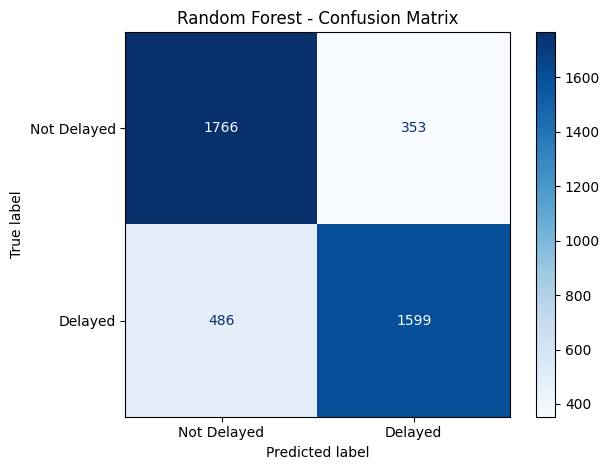

In [26]:
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=None,
    min_samples_leaf=5,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)
y_pred_rf = rf_model.predict(X_test)

print("Random Forest")
print(classification_report(y_test, y_pred_rf, target_names=["Not Delayed", "Delayed"]))
print(f"Train accuracy: {rf_model.score(X_train, y_train):.4f}")
print(f"Test accuracy:  {rf_model.score(X_test, y_test):.4f}")

# Confusion matrix
cm = confusion_matrix(y_test, y_pred_rf)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Not Delayed", "Delayed"])
disp.plot(cmap="Blues")
plt.title("Random Forest - Confusion Matrix")
plt.tight_layout()
plt.show()

## XGBoost

XGBoost Classification
              precision    recall  f1-score   support

 Not Delayed       0.76      0.83      0.79      2119
     Delayed       0.81      0.73      0.77      2085

    accuracy                           0.78      4204
   macro avg       0.78      0.78      0.78      4204
weighted avg       0.78      0.78      0.78      4204

Train accuracy: 0.8449
Test accuracy:  0.7788


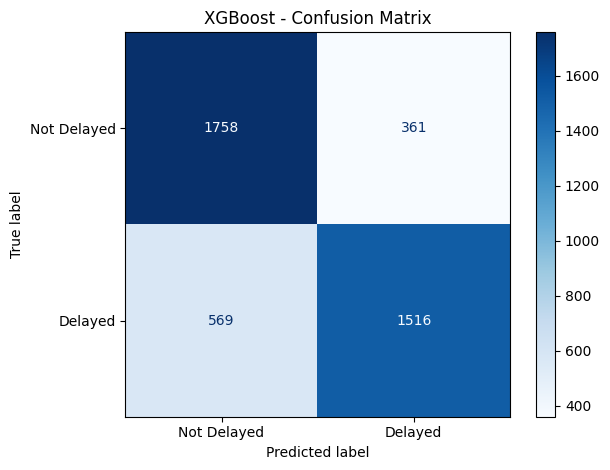

In [27]:
xgb_model = XGBClassifier(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=(y_train == 0).sum() / (y_train == 1).sum(),
    random_state=42,
    n_jobs=-1,
    eval_metric="logloss"
)

xgb_model.fit(X_train, y_train)
y_pred_xgb = xgb_model.predict(X_test)

print("XGBoost Classification")
print(classification_report(y_test, y_pred_xgb, target_names=["Not Delayed", "Delayed"]))
print(f"Train accuracy: {xgb_model.score(X_train, y_train):.4f}")
print(f"Test accuracy:  {xgb_model.score(X_test, y_test):.4f}")

cm_xgb = confusion_matrix(y_test, y_pred_xgb)
disp_xgb = ConfusionMatrixDisplay(confusion_matrix=cm_xgb, display_labels=["Not Delayed", "Delayed"])
disp_xgb.plot(cmap="Blues")
plt.title("XGBoost - Confusion Matrix")
plt.tight_layout()
plt.show()

## Feature Selection


In [28]:
# Run permutation importance on both models
perm_imp_rf = permutation_importance(
    rf_model, X_test, y_test,
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

perm_imp_xgb = permutation_importance(
    xgb_model, X_test, y_test,
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

# Create dataframes for easy viewing
perm_rf_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": perm_imp_rf.importances_mean,
    "Std": perm_imp_rf.importances_std
}).sort_values("Importance", ascending=False)

perm_xgb_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": perm_imp_xgb.importances_mean,
    "Std": perm_imp_xgb.importances_std
}).sort_values("Importance", ascending=False)

print("=== Random Forest Permutation Importance ===")
print(perm_rf_df.to_string(index=False))

print("\n=== XGBoost Permutation Importance ===")
print(perm_xgb_df.to_string(index=False))

=== Random Forest Permutation Importance ===
                     Feature  Importance      Std
                  Order City    0.108587 0.004040
               Customer City    0.107184 0.004450
  Shipping Mode_Second Class    0.083254 0.005464
                    Latitude    0.068673 0.002798
                   Longitude    0.060276 0.001749
                 Order State    0.051261 0.002937
                Order Region    0.031898 0.003393
              Customer State    0.028711 0.001761
Shipping Mode_Standard Class    0.021028 0.002452
            Customer Country    0.008468 0.001400
      Shipping Mode_Same Day    0.002831 0.000677
    Department Name_Footwear    0.000809 0.000657
    Department Name_Outdoors   -0.000238 0.000521
     Department Name_Fitness   -0.000285 0.000316
    Department Name_Fan Shop   -0.001903 0.001542
        Department Name_Golf   -0.001951 0.000856
     Department Name_Apparel   -0.003877 0.001783

=== XGBoost Permutation Importance ===
               

In [29]:
# Selected features based on permutation importance
selected_features = [
    "Customer City", "Customer State",
    "Order City", "Order State", "Order Region",
    "Shipping Mode_Standard Class",
    "Shipping Mode_Same Day", "Shipping Mode_Second Class"
]

X_train_selected = X_train[selected_features]
X_test_selected = X_test[selected_features]

print(f"Features reduced from {X_train.shape[1]} to {X_train_selected.shape[1]}")

Features reduced from 17 to 8


In [30]:
# Random Forest
rf_model_v2 = RandomForestClassifier(
    n_estimators=300,
    max_features=0.5,
    max_depth=None,
    min_samples_leaf=3,
    min_samples_split=5,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)
rf_model_v2.fit(X_train_selected, y_train)
y_pred_rf_v2 = rf_model_v2.predict(X_test_selected)

xgb_model_v2 = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    min_child_weight=3,
    reg_alpha=0.1,
    reg_lambda=1.0,
    scale_pos_weight=(y_train == 0).sum() / (y_train == 1).sum(),
    random_state=42,
    n_jobs=-1,
    eval_metric="logloss"
)
xgb_model_v2.fit(X_train_selected, y_train)
y_pred_xgb_v2 = xgb_model_v2.predict(X_test_selected)

# Compare results
print("=== Random Forest v2 ===")
print(classification_report(y_test, y_pred_rf_v2, target_names=["Not Delayed", "Delayed"]))
print(f"Train accuracy: {rf_model_v2.score(X_train_selected, y_train):.4f}")
print(f"Test accuracy:  {rf_model_v2.score(X_test_selected, y_test):.4f}")

print("\n=== XGBoost v2 ===")
print(classification_report(y_test, y_pred_xgb_v2, target_names=["Not Delayed", "Delayed"]))
print(f"Train accuracy: {xgb_model_v2.score(X_train_selected, y_train):.4f}")
print(f"Test accuracy:  {xgb_model_v2.score(X_test_selected, y_test):.4f}")

=== Random Forest v2 ===
              precision    recall  f1-score   support

 Not Delayed       0.79      0.84      0.81      2119
     Delayed       0.83      0.77      0.80      2085

    accuracy                           0.81      4204
   macro avg       0.81      0.81      0.81      4204
weighted avg       0.81      0.81      0.81      4204

Train accuracy: 0.8625
Test accuracy:  0.8057

=== XGBoost v2 ===
              precision    recall  f1-score   support

 Not Delayed       0.73      0.83      0.78      2119
     Delayed       0.80      0.69      0.74      2085

    accuracy                           0.76      4204
   macro avg       0.77      0.76      0.76      4204
weighted avg       0.77      0.76      0.76      4204

Train accuracy: 0.8057
Test accuracy:  0.7607


In [31]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint

# ── Random Forest Grid Search ──
rf_param_grid = {
    "n_estimators": [200, 300, 500],
    "max_depth": [15, 20, 25, None],
    "min_samples_leaf": [3, 5, 10],
    "min_samples_split": [2, 5, 10],
    "max_features": [0.5, 0.7, 0.8, None],
}

rf_search = RandomizedSearchCV(
    RandomForestClassifier(class_weight="balanced", random_state=42, n_jobs=-1),
    param_distributions=rf_param_grid,
    n_iter=30,
    cv=5,
    scoring="f1_weighted",
    random_state=42,
    n_jobs=-1,
    verbose=1
)

rf_search.fit(X_train_selected, y_train)

print("=== Best Random Forest Parameters ===")
print(rf_search.best_params_)
print(f"Best CV F1: {rf_search.best_score_:.4f}")

# ── XGBoost Grid Search ──
xgb_param_grid = {
    "n_estimators": [100, 200, 300],
    "max_depth": [4, 6, 8],
    "learning_rate": [0.05, 0.1, 0.2],
    "subsample": [0.7, 0.8, 0.9],
    "colsample_bytree": [0.7, 0.8, 0.9],
    "min_child_weight": [1, 3, 5],
    "reg_alpha": [0, 0.1, 1.0],
    "reg_lambda": [1.0, 3.0, 5.0],
}

xgb_search = RandomizedSearchCV(
    XGBClassifier(
        scale_pos_weight=(y_train == 0).sum() / (y_train == 1).sum(),
        random_state=42,
        n_jobs=-1,
        eval_metric="logloss"
    ),
    param_distributions=xgb_param_grid,
    n_iter=30,
    cv=5,
    scoring="f1_weighted",
    random_state=42,
    n_jobs=-1,
    verbose=1
)

xgb_search.fit(X_train_selected, y_train)

print("\n=== Best XGBoost Parameters ===")
print(xgb_search.best_params_)
print(f"Best CV F1: {xgb_search.best_score_:.4f}")

Fitting 5 folds for each of 30 candidates, totalling 150 fits
=== Best Random Forest Parameters ===
{'n_estimators': 500, 'min_samples_split': 5, 'min_samples_leaf': 3, 'max_features': 0.8, 'max_depth': 25}
Best CV F1: 0.8011
Fitting 5 folds for each of 30 candidates, totalling 150 fits

=== Best XGBoost Parameters ===
{'subsample': 0.7, 'reg_lambda': 5.0, 'reg_alpha': 1.0, 'n_estimators': 300, 'min_child_weight': 1, 'max_depth': 8, 'learning_rate': 0.2, 'colsample_bytree': 0.9}
Best CV F1: 0.8046


In [32]:
print(rf_search.best_params_)

{'n_estimators': 500, 'min_samples_split': 5, 'min_samples_leaf': 3, 'max_features': 0.8, 'max_depth': 25}


In [33]:
# Best Random Forest
rf_best = rf_search.best_estimator_
y_pred_rf_best = rf_best.predict(X_test_selected)

# Best XGBoost
xgb_best = xgb_search.best_estimator_
y_pred_xgb_best = xgb_best.predict(X_test_selected)

print("=== Random Forest ===")
print(classification_report(y_test, y_pred_rf_best, target_names=["Not Delayed", "Delayed"]))
print(f"Test accuracy:  {rf_best.score(X_test_selected, y_test):.4f}")

print("\n=== XGBoost ===")
print(classification_report(y_test, y_pred_xgb_best, target_names=["Not Delayed", "Delayed"]))
print(f"Test accuracy:  {xgb_best.score(X_test_selected, y_test):.4f}")

=== Random Forest ===
              precision    recall  f1-score   support

 Not Delayed       0.79      0.85      0.82      2119
     Delayed       0.84      0.77      0.80      2085

    accuracy                           0.81      4204
   macro avg       0.81      0.81      0.81      4204
weighted avg       0.81      0.81      0.81      4204

Test accuracy:  0.8102

=== XGBoost ===
              precision    recall  f1-score   support

 Not Delayed       0.79      0.87      0.83      2119
     Delayed       0.85      0.77      0.81      2085

    accuracy                           0.82      4204
   macro avg       0.82      0.82      0.82      4204
weighted avg       0.82      0.82      0.82      4204

Test accuracy:  0.8192


In [34]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Random Forest CV
rf_cv_scores = cross_val_score(
    rf_best, X_train_selected, y_train,
    cv=cv,
    scoring="f1_weighted",
    n_jobs=-1
)

# XGBoost CV
xgb_cv_scores = cross_val_score(
    xgb_best, X_train_selected, y_train,
    cv=cv,
    scoring="f1_weighted",
    n_jobs=-1
)

print("=== Random Forest Cross-Validation ===")
print(f"F1 per fold: {rf_cv_scores.round(4)}")
print(f"Mean F1:     {rf_cv_scores.mean():.4f}")
print(f"Std F1:      {rf_cv_scores.std():.4f}")
print(f"95% CI:      ({rf_cv_scores.mean() - 2*rf_cv_scores.std():.4f}, "
      f"{rf_cv_scores.mean() + 2*rf_cv_scores.std():.4f})")

print("\n=== XGBoost Cross-Validation ===")
print(f"F1 per fold: {xgb_cv_scores.round(4)}")
print(f"Mean F1:     {xgb_cv_scores.mean():.4f}")
print(f"Std F1:      {xgb_cv_scores.std():.4f}")
print(f"95% CI:      ({xgb_cv_scores.mean() - 2*xgb_cv_scores.std():.4f}, "
      f"{xgb_cv_scores.mean() + 2*xgb_cv_scores.std():.4f})")

=== Random Forest Cross-Validation ===
F1 per fold: [0.7948 0.8077 0.8039 0.809  0.7901]
Mean F1:     0.8011
Std F1:      0.0074
95% CI:      (0.7863, 0.8159)

=== XGBoost Cross-Validation ===
F1 per fold: [0.796  0.8104 0.8027 0.8158 0.7933]
Mean F1:     0.8036
Std F1:      0.0085
95% CI:      (0.7867, 0.8206)


## Validation SHAP


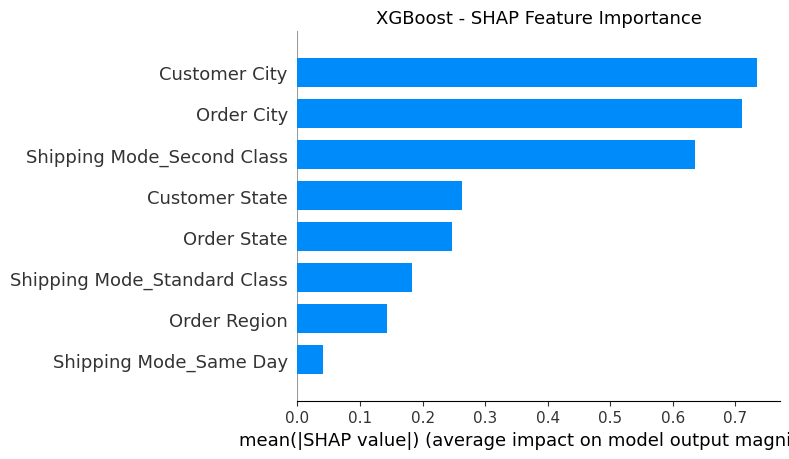

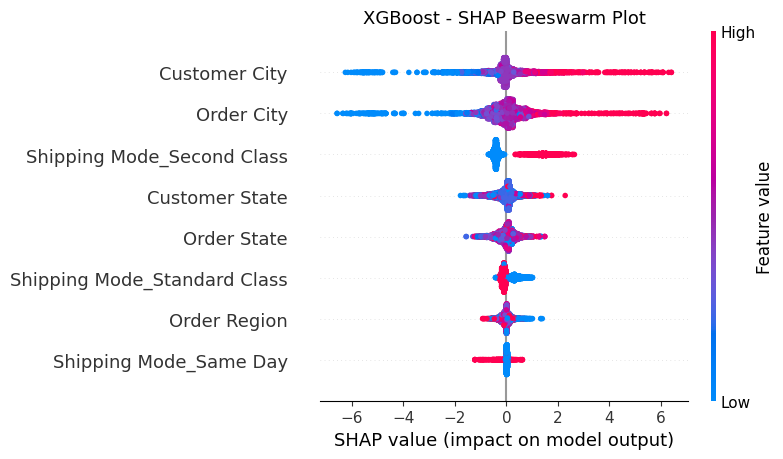

In [35]:
import shap

# Use XGBoost as primary model since it's your best performer
explainer = shap.TreeExplainer(xgb_best)
shap_values = explainer.shap_values(X_test_selected)

# Summary plot - overall feature importance
plt.figure()
shap.summary_plot(
    shap_values, 
    X_test_selected,
    plot_type="bar",
    show=False
)
plt.title("XGBoost - SHAP Feature Importance", fontsize=13)
plt.tight_layout()
plt.show()

# Beeswarm plot - shows direction of impact
plt.figure()
shap.summary_plot(
    shap_values,
    X_test_selected,
    show=False
)
plt.title("XGBoost - SHAP Beeswarm Plot", fontsize=13)
plt.tight_layout()
plt.show()

In [36]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score

# Logistic Regression (linear model)
log_reg = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42)
log_reg.fit(X_train_selected, y_train)
y_pred_log = log_reg.predict(X_test_selected)

print("=== Logistic Regression (Linear) ===")
print(f"Accuracy: {accuracy_score(y_test, y_pred_log):.4f}")
print(f"F1 Score: {f1_score(y_test, y_pred_log, average='weighted'):.4f}")

print("\n=== XGBoost (Non-Linear) ===")
print(f"Accuracy: {xgb_best.score(X_test_selected, y_test):.4f}")
print(f"F1 Score: {f1_score(y_test, y_pred_xgb_best, average='weighted'):.4f}")

=== Logistic Regression (Linear) ===
Accuracy: 0.6832
F1 Score: 0.6813

=== XGBoost (Non-Linear) ===
Accuracy: 0.8192
F1 Score: 0.8187


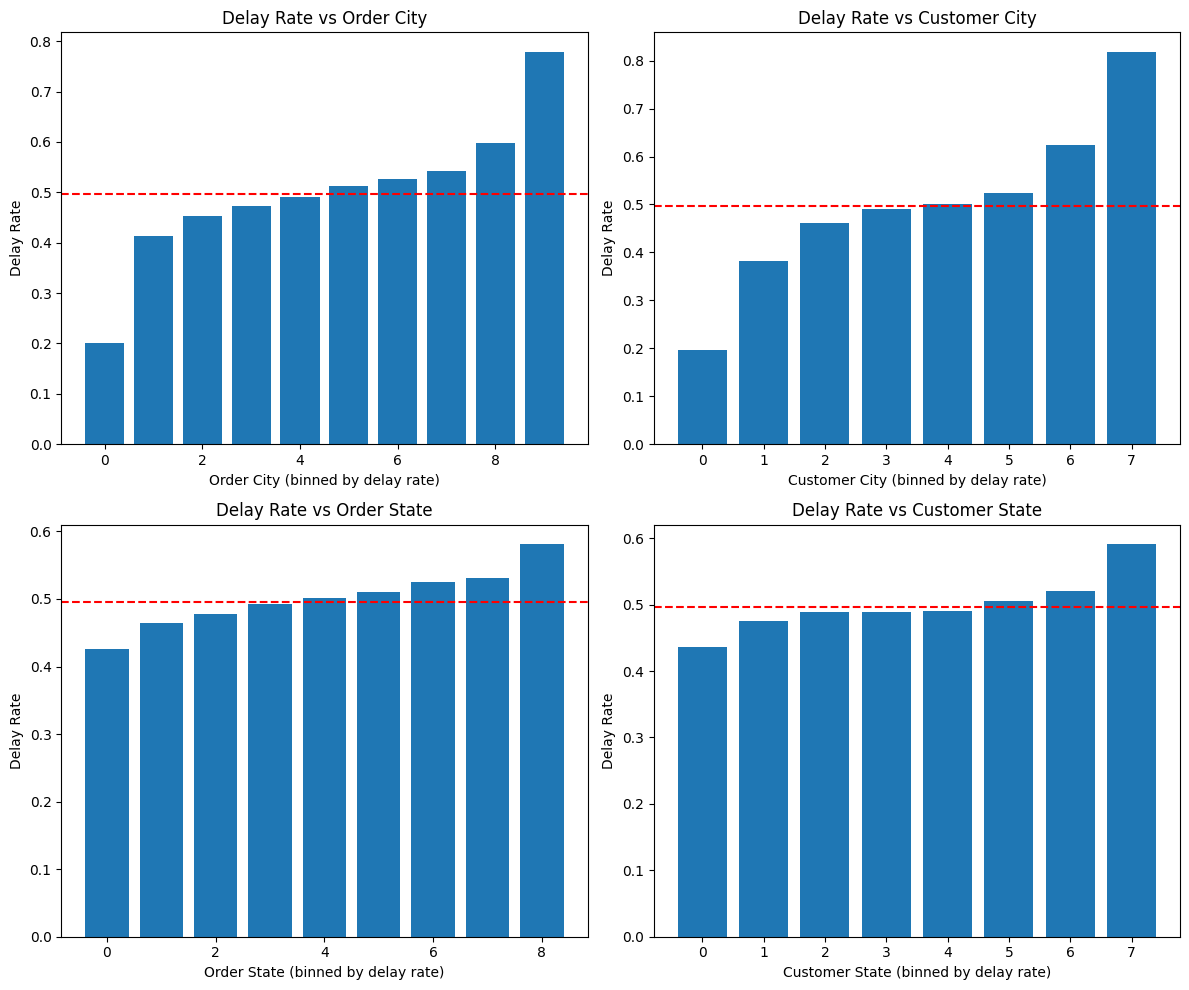

In [37]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

# Plot delay rate by binned feature values
for idx, col in enumerate(['Order City', 'Customer City', 'Order State', 'Customer State']):
    ax = axes[idx // 2, idx % 2]
    
    # Bin the target-encoded values
    bins = pd.qcut(X_train_selected[col], q=10, duplicates='drop')
    delay_by_bin = y_train.groupby(bins).mean()
    
    ax.bar(range(len(delay_by_bin)), delay_by_bin.values)
    ax.set_xlabel(f'{col} (binned by delay rate)')
    ax.set_ylabel('Delay Rate')
    ax.set_title(f'Delay Rate vs {col}')
    ax.axhline(y=y_train.mean(), color='r', linestyle='--', label='Overall mean')

plt.tight_layout()
plt.show()

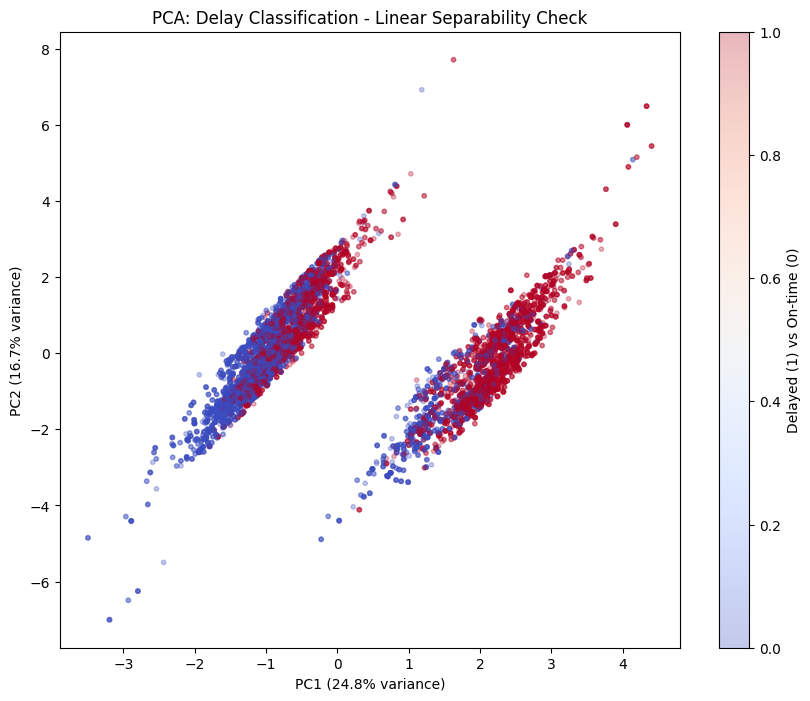

In [38]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Scale features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_train_selected)

# Reduce to 2D
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# Plot
plt.figure(figsize=(10, 8))
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y_train, cmap='coolwarm', alpha=0.3, s=10)
plt.colorbar(scatter, label='Delayed (1) vs On-time (0)')
plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.1%} variance)')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.1%} variance)')
plt.title('PCA: Delay Classification - Linear Separability Check')
plt.show()